<a href="https://colab.research.google.com/github/Ben-AC-Math/Generalisable_PI/blob/master/PIPN_simpler_pointnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Set the working directory for the Code. 

In [1]:
%cd /content/drive/MyDrive/PIPN#

[Errno 2] No such file or directory: '/content/drive/MyDrive/PIPN#'
/content


Import relevant packages/libraries

In [2]:
import os
import numpy as np
import itertools
import math, random
random.seed = 42
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
from torch.autograd import grad, Variable
import torch.optim as optim
from sklearn.preprocessing import normalize

import time
import scipy.io

import matplotlib.pyplot as plt
import matplotlib.tri as tri

Point Sampler for the Kaggle implementation

In [3]:
class PointSampler(object):
    def __init__(self, output_size):
        assert isinstance(output_size, int)
        self.output_size = output_size

    def __call__(self, points):

        sampled_points = points[np.random.choice(points.shape[0], self.output_size), :]

        sampled_points_normalized = normalize(sampled_points, norm='l2')
       
        return sampled_points

class Normalize(object):
    def __call__(self, pointcloud):
        assert len(pointcloud.shape)==2
        
        norm_pointcloud = pointcloud 
        
        return  norm_pointcloud

class ToTensor(object):
    def __call__(self, pointcloud):
        assert len(pointcloud.shape)==2

        return torch.from_numpy(pointcloud)

def default_transforms():
  return transforms.Compose([
                            PointSampler(256),
                            Normalize(),
                            ToTensor()
                          ])

Method for importing our data. Each mesh needs to be in the meshes folder and each mesh should be labelled as v1, v2, vn. Currently the code assumes that there are 3 files in the folder: 'Ux.txt', 'Uy.txt' and 'elements.txt'

In [4]:
class test_PointCloudData(Dataset):
    def __init__(self, root_dir, valid=False, folder="test", transform=default_transforms()):
        self.root_dir = root_dir
        self.scaler = MinMaxScaler()
        self.pointSampler = PointSampler(output_size=5000)
        self.bc_pointSampler = PointSampler(output_size=5000)
        folders = os.listdir(root_dir)
        self.transforms = transform if not valid else default_transforms()
        self.files = []

        for version in folders:
          version_path = os.path.join(self.root_dir, version)

          sample = {}
          sample['Ux'] = os.path.join(version_path, 'Ux.txt')
          sample['Uy'] = os.path.join(version_path, 'Uy.txt')
          #sample['elements'] = os.path.join(version_path, 'elements.txt')
          self.files.append(sample)

        print(self.files)   
       

    def __len__(self):
        return len(self.files)


    def __getitem__(self, idx):
      ux_path = self.files[idx]['Ux']
      uy_path = self.files[idx]['Uy']
      #ele_path = self.files[idx]['elements']
      # print("input feature", np.array(pd.read_csv(ux_path)).shape)
      input_feature = np.array(pd.read_csv(ux_path))
      #elements = np.array(pd.read_csv(ele_path, delimiter = "\t"))[:,0:3].astype(int)
      #elements = elements - 1
      ux = np.array(pd.read_csv(ux_path))[:,2]
      uy = np.array(pd.read_csv(uy_path))[:,2]
      uz = np.zeros((uy.shape[0],1))

      displacement = np.concatenate((ux[:,np.newaxis], uy[:,np.newaxis], uz), axis=1)

      

      # Create a boolean index that is True for rows where the value in the 3rd column is 1 
      index = (input_feature[:, 1] == 1)

      #BCs is a 3 column array (x,y,z) vectors of displacement BCs or could just be a one column?
      boundary_conditions = np.zeros((input_feature.shape[0],1))
      #print('BC', boundary_conditions)

      # Create a new column with all values set to 0
      bc_present = np.zeros((input_feature.shape[0], 1))

      # Set the values in to 0.5 when y = 10
      boundary_conditions[index] = 0.05

      # Create a boolean index that is True for rows where the value in the 3rd column is 0 or 1
      index = (input_feature[:, 1] < 0.0001) | (input_feature[:, 1] == 1)

      # Set the values in the new column to 1 for rows where the index is True
      bc_present[index] = 1

      #print('input_feature :', input_feature.shape)

      #finding x_b
      x_b = input_feature[index]
      y_b = displacement[index]

      #print('xb', x_b)

      #print('x_b :', x_b.shape)       

      index_2 = [not elem for elem in index]
      
      x = input_feature[index_2]
      #print('x :', x.shape)
      y = displacement[index_2]

      # Concatenate the old array and the new column to create the new array
      #input_feature = np.concatenate((input_feature, bc_present, boundary_conditions), axis=1)

      sampled_input_output = np.concatenate((x, y), axis=1)
      sampled_bc = np.concatenate((x_b, y_b), axis=1)

      sampled_input_output = self.pointSampler(sampled_input_output)
      sampled_bc = self.bc_pointSampler(sampled_bc)

      sampled_x = sampled_input_output[:,:2]
      sampled_y= sampled_input_output[:,-2:]

      sampled_x_b = sampled_bc[:,:2]
      sampled_y_b = sampled_bc[:,-2:]

      #input_coords = sampled_input_feature[:, :3]
      #bc = sampled_input_feature[:,-2:]

      #input_feature = self.scaler.fit_transform(input_feature)
      
      sampled_x = torch.from_numpy(sampled_x)
      sampled_y = torch.from_numpy(sampled_y)

      sampled_x_b = torch.from_numpy(sampled_x_b)
      sampled_y_b = torch.from_numpy(sampled_y_b)
      #input_coords = torch.from_numpy(input_coords)
      
      return {'x': sampled_x, 'y': sampled_y, 'x_b':sampled_x_b, 'y_b':sampled_y_b}

In [5]:
class PointCloudData(Dataset):
    def __init__(self, root_dir, valid=False, folder="test", transform=default_transforms()):
        self.root_dir = root_dir
        self.scaler = MinMaxScaler()
        self.pointSampler = PointSampler(output_size=512)
        self.bc_pointSampler = PointSampler(output_size=512)
        folders = os.listdir(root_dir)
        self.transforms = transform if not valid else default_transforms()
        self.files = []

        for version in folders:
            version_path = os.path.join(self.root_dir, version)

            sample = {}
            sample['Ux'] = os.path.join(version_path, 'Ux.txt')
            sample['Uy'] = os.path.join(version_path, 'Uy.txt')
            self.files.append((sample))  

        #print(self.files)   
       

    def __len__(self):
        return len(self.files)


    def __getitem__(self, idx):
        #finding max x coordinates and radius of the hole
        #print(self.files[idx])
        version = os.path.basename(os.path.dirname(self.files[idx]['Ux']))
        x_max, hole_radius = version.split("_")[1:]
        x_max = float(x_max)
        hole_radius = float(hole_radius)

        #inputting paths for the point coordinates and displacements (x, y, u) & (x, y, v)
        ux_path = self.files[idx]['Ux']
        uy_path = self.files[idx]['Uy']

        #input_feature should only have point coordinates 
        input_feature = np.array(pd.read_csv(ux_path, skiprows=1))
        input_feature[:,2] = 0

        #displacement is our ground truth
        ux = np.array(pd.read_csv(ux_path, skiprows=1))[:,2]
        uy = np.array(pd.read_csv(uy_path, skiprows=1))[:,2]
        uz = np.zeros((uy.shape[0],1))
        displacement = np.concatenate((ux[:,np.newaxis], uy[:,np.newaxis], uz), axis=1)

        # Calculate the distance of each point from the origin (0, 0), tells us which points line on hole
        distance = np.sqrt(input_feature[:, 0]**2 + input_feature[:, 1]**2)
       
        #index is used to find points on boundary. Currently looks at points at y = 0 and y = 1
        #needs to include points at x_min, x_max and the on the radius of the whole
        index = (input_feature[:, 1] < 0.0001) | (input_feature[:, 1] > 0.999) | (input_feature[:, 0] < 0.0001) | (input_feature[:, 0] > 0.999*x_max) | (distance < hole_radius + 1e-4)
        
        x_b = input_feature[index]
        y_b = displacement[index]

        #index_2 is for internal points
        index_2 = [not elem for elem in index]
        x = input_feature[index_2]
        y = displacement[index_2]

        sampled_input_output = self.pointSampler(np.concatenate((x, y), axis=1))
        sampled_bc = self.bc_pointSampler(np.concatenate((x_b, y_b), axis=1))

        #taking 2D
        sampled_x = torch.from_numpy(sampled_input_output[:,:2])
        sampled_y= torch.from_numpy(sampled_input_output[:,-2:])

        sampled_x_b = torch.from_numpy(sampled_bc[:,:2])
        sampled_y_b = torch.from_numpy(sampled_bc[:,-2:])

        return {'x': sampled_x, 'y': sampled_y, 'x_b':sampled_x_b, 'y_b':sampled_y_b}


Test_PointCloudData is used to import data from the example PINN. This is not for our data!

Checking size of input data. Each mesh should have shape of [num_points, num_input_features] for input and [num_points, num_output_features] for the output

In [6]:
# Uncomment below if you want to run with our data, remind to change loss function!
pointDataset_train = PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Training')
pointDataset_val = PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Validation')
#pointDataset_test = test_PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Testing')
print(len(pointDataset_train))
print(len(pointDataset_val))
#print(len(pointDataset_test))


# for i in range(len(pointDataset_train)):
#   print(pointDataset_train[i]['x'].shape)
#   print(pointDataset_train[i]['y'].shape)
#   print(pointDataset_train[i]['y_b'].shape)
# #   #print('inputcoords:', pointDataset_train[i]['inputcoords'].shape)



60
60


Loading the dataset for the training. Need to initiate the validation loader. 


In [7]:
train_loader = DataLoader(dataset=pointDataset_train, batch_size=4, shuffle=True)

valid_loader = DataLoader(dataset=pointDataset_val, batch_size=8, shuffle=False)




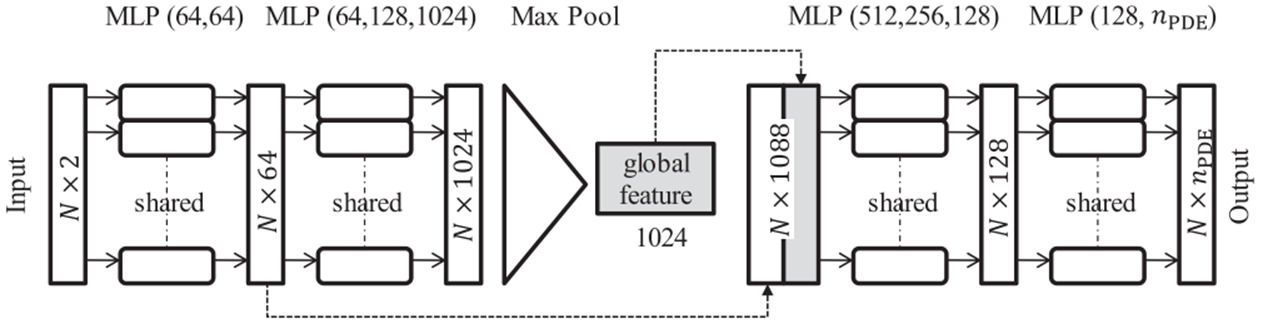

In [8]:
class Tnet(nn.Module):
    def __init__(self, k=2):
        super().__init__()
        self.k=k
        self.conv1 = nn.Conv1d(k,64,1)
        self.conv2 = nn.Conv1d(64,64,1)
        self.conv3 = nn.Conv1d(64,64,1)
        self.fc1 = nn.Conv1d(64,128,1)
        self.fc2 = nn.Conv1d(128,1024,1)

        self.bn1 = nn.BatchNorm1d(64)
        self.bn2 = nn.BatchNorm1d(64)
        self.bn3 = nn.BatchNorm1d(64)
        self.bn4 = nn.BatchNorm1d(128)
        self.bn5 = nn.BatchNorm1d(1024)

    def forward(self, input):
        # input.shape == (bs,n,3)
        bs = input.size(0)
        xb = torch.tanh(self.bn1(self.conv1(input)))
        out_t2 = torch.tanh(self.bn2(self.conv2(xb)))
        xb = torch.tanh(self.bn3(self.conv3(out_t2)))
        xb = torch.tanh(self.bn4(self.fc1(xb)))
        xb = torch.tanh(self.bn5(self.fc2(xb)))
        #print('xb:', xb.shape)

        pool = nn.MaxPool1d(xb.size(-1))(xb)
        #print('pool:', pool.shape)
        output = nn.Flatten(1)(pool)
        #print('output dim:', output.shape)
        output = output.view(-1, 1024, 1).repeat(1, 1, input.shape[2])

        #print('output dim:', output.shape)
        #print('out_t2 dim:', out_t2.shape)
        concat_out = torch.cat([out_t2, output], dim=1)

        # print('concat_out dim:', concat_out.shape)

        return concat_out


class PointNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_transform = Tnet(k=2)
        self.fc1 = nn.Conv1d(1088, 512, 1)
        self.fc2 = nn.Conv1d(512, 256, 1)
        self.fc3 = nn.Conv1d(256, 128, 1)
        self.fc4 = nn.Conv1d(128, 128, 1)
        self.fc5 = nn.Conv1d(128, 2, 1)

        self.bn1 = nn.BatchNorm1d(512)
        self.bn2 = nn.BatchNorm1d(256)
        self.bn3 = nn.BatchNorm1d(128)
        self.bn4 = nn.BatchNorm1d(128)
    
        #self.dropout = nn.Dropout(p=0.3)

    def forward(self, input):
        # print('input shape (PointNet):', input.shape)
        xb = self.input_transform(input)
        xb = torch.tanh(self.bn1(self.fc1(xb)))
        xb = torch.tanh(self.bn2(self.fc2(xb)))
        xb = torch.tanh(self.bn3(self.fc3(xb)))
        xb = torch.tanh(self.bn4(self.fc4(xb)))

        output = self.fc5(xb)

        return output

Here I call the pointnet and pass the inputs through the network to check on the desired shape

In [9]:
pointnet = PointNet()

for i, data in enumerate(train_loader, 0):
  #print(data.size(0))
  inputs, labels = data['x'].float(), data['y'].float()
  inputs  = inputs.transpose(1,2)
  labels = labels.transpose(1,2)

  outputs = pointnet(inputs)

Here the hyperparameters can be assainged 

In [10]:
lr = 0.004
patience = 50
start_epoch = 1
epochs = 1000
print_freq = 20
save_folder = '/content/drive/MyDrive/PIPN/saved_models'

The custom training function is outlined below. It has training and validation loop inside. 

In [11]:
# how to calculate the loss for each epoch => https://discuss.pytorch.org/t/plotting-loss-curve/42632
def train(train_loader, model, optimizer, criterion, epoch):
    # Ensure dropout layers are in train mode
    model.train()
    
    running_loss = 0.0
    running_mse_loss = 0.0
    running_pinn_loss = 0.0

    # Batches
    # here train_loader returns only x since we use CustomDataset calss and __getitem__ returns only x
    for i_batch, data in enumerate(train_loader):

        x, y, x_b, y_b = data['x'].to(device).float(), data['y'].to(device).float(), data['x_b'].to(device).float(), data['y_b'].to(device).float()
        x  = x.transpose(1,2)
        y = y.transpose(1,2)
        x_b  = x_b.transpose(1,2)
        y_b = y_b.transpose(1,2)

        b_u = y_b[:,0,:]
        b_v = y_b[:,1,:]
        
        # Zero gradients
        optimizer.zero_grad()

        x_train = x.clone().detach().requires_grad_(True)
        xb_train = x_b.clone().detach().requires_grad_(True)
        # coords_variable = coords.clone().detach().requires_grad_(True)# print the created tensors
        y_hat = model(x)

        #print(xs.grad)
      
        #x_coords = data.pos.to(device)

        multitask_loss, mse_loss, pinn_loss = criterion(y_hat, y, x_train, xb_train, b_u, b_v, model, epoch)
        
        # pinn_loss = torch.mul(pinn_loss, 1)

        # multitask_loss = torch.add(mse_loss, pinn_loss)

        multitask_loss.backward()
        #multitask_loss.backward(torch.ones_like(multitask_loss))

        #print('PINN loss shpae: ',pinn_loss.shape)

        optimizer.step()
        # this can be used if your all batches have equal number of data points including the last batch
        # running_loss += loss.item()
        # if the last batch is smaller than the others
        # data.num_graphs gives the number of graphs per data or batch
        running_loss += multitask_loss.item() * data['x'].shape[0]
        #running_loss += torch.tensor(multitask_loss) * data['pointfeature'].shape[0]
        #running_chamfer_loss += chamfer_loss.item() * data.num_graphs
        running_mse_loss += mse_loss.item() * data['x'].shape[0]
        running_pinn_loss += pinn_loss.item() * data['x'].shape[0]
        #running_pinn_loss += torch.tensor(pinn_loss) * data['pointfeature'].shape[0]
 

    # average training loss => total loss for each epoch (compute by taking sum of each batch loss) devide by total number of batches (i.e. len(train_loader))
    # loss = running_loss / len(train_loader)
    # If you just would like to plot the loss for each epoch, divide the running_loss by the number of batches and append it to loss_values in each epoch.
    # Note, that this might give you a slightly biased loss if the last batch is smaller than the others, so let me know if you need the exact loss.
    # len(train_loader.dataset) gives total number of graphs in the training dataset
    loss = running_loss / len(train_loader.dataset)
    #loss_chamfer = running_chamfer_loss / len(train_loader.dataset)
    loss_mse = running_mse_loss / len(train_loader.dataset)
    loss_pinn = running_pinn_loss / len(train_loader.dataset)

    # print('average total loss:', loss)
    # print('average mse loss:', loss_mse)
    # print('average pinn loss:', loss_pinn)
    
    return loss, loss_mse, loss_pinn
    #return loss, loss_mse
	
	
	
def valid(val_loader, model, optimizer, validMSE, epoch):
    model.eval()  # eval mode (no dropout or batchnorm)
    
    running_val_loss = 0.0
    running_mse_loss = 0.0
    running_pinn_loss = 0.0

    
    # Batches
    # here val_loader returns only x since we use CustomDataset class and __getitem__ returns only x
    for i_batch, data in enumerate(val_loader):
        # Set device options
        x, y, x_b, y_b = data['x'].to(device).float(), data['y'].to(device).float(), data['x_b'].to(device).float(), data['y_b'].to(device).float()
        x  = x.transpose(1,2)
        y = y.transpose(1,2)
        x_b  = x_b.transpose(1,2)
        y_b = y_b.transpose(1,2)

        b_u = y_b[:,0,:]
        b_v = y_b[:,1,:]
        
        # Zero gradients
        optimizer.zero_grad()

        x_valid = x.clone().detach().requires_grad_(True)
        xb_valid = x_b.clone().detach().requires_grad_(True)

        y_hat = model(x)

        # multitask_loss = validMSE(y_hat, y)
        # multitask_loss = torch.mul(multitask_loss, 1)
        multitask_loss, mse_loss, pinn_loss = criterion(y_hat, y, x_valid, xb_valid, b_u , b_v, model, epoch)

        running_val_loss += multitask_loss.item() * data['x'].shape[0]
        running_mse_loss += mse_loss.item() * data['x'].shape[0]
        running_pinn_loss += pinn_loss.item() * data['x'].shape[0]

        def apply_mask(triang, x, y, alpha=0.4):
          # Mask triangles with sidelength bigger than some alpha. You'll have to play around with the alpha to get it right
          triangles = triang.triangles
          # Mask off unwanted triangles.
          xtri = x[triangles] - np.roll(x[triangles], 1, axis=1)
          ytri = y[triangles] - np.roll(y[triangles], 1, axis=1)
          maxi = np.max(np.sqrt(xtri**2 + ytri**2), axis=1)
          # apply masking
          triang.set_mask(maxi > alpha)
          
        x_coord = x[0, 0,:].detach().cpu().numpy()
        y_coord = x[0, 1,:].detach().cpu().numpy()
        u = y_hat[0, 0,:].detach().cpu().numpy()
        u_gt = y[0, 0,:].detach().cpu().numpy()

        if i_batch == 1:
          # x, y are the x and y coords you want to plot at (can use the same form you have your training data in already),
          # u would be whatever variable you want to plot
          triang = tri.Triangulation(x_coord, y_coord)
          apply_mask(triang, x_coord, y_coord, alpha=0.5)
          fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 10))
          tcf_a = axes[0].tricontourf(triang, u_gt, cmap='RdYlBu_r', levels=100)
          fig.colorbar(tcf_a, ax=axes[0])
          axes[0].set_title('Ground Truth')

          tcf = axes[1].tricontourf(triang, u, cmap='RdYlBu_r', levels=tcf_a.levels)
          fig.colorbar(tcf, ax=axes[1])
          axes[1].set_title('Prediction')

          print("################################################################")

          plt.show()
          plt.close()
          
        else:
          None

    val_loss = running_val_loss / len(val_loader.dataset)
    loss_mse = running_mse_loss / len(val_loader.dataset)
    loss_pinn = running_pinn_loss / len(val_loader.dataset)

    return val_loss, loss_mse, loss_pinn
	
	
	
def save_checkpoint(epoch, model, optimizer, val_loss, is_best):
    ensure_folder(save_folder)
    state = {'epoch': epoch,
             'model_state_dict': model.state_dict(),
             'optimizer_state_dict': optimizer.state_dict()}
    filename = '{0}/checkpoint_{1}_{2:.3f}.tar'.format(save_folder, epoch, val_loss)
    torch.save(model.state_dict(), filename)
    # If this checkpoint is the best so far, store a copy so it doesn't get overwritten by a worse checkpoint
    if is_best:
        torch.save(state, '{}/BEST_checkpoint.tar'.format(save_folder))
		
		
def ensure_folder(folder):
    if not os.path.exists(folder):
        os.makedirs(folder)
		
		
def adjust_learning_rate(optimizer, shrink_factor):
    print("\nDECAYING learning rate.")
    for param_group in optimizer.param_groups:
        param_group['lr'] = param_group['lr'] * shrink_factor
    print("The new learning rate is %f\n" % (optimizer.param_groups[0]['lr'],))

Loss functions are defined in the classes below. Two loss functions are employed. One for the observational learning and one for the physics learning. 

In [12]:

class PinnLoss(nn.Module):
    def __init__(self):
        super(PinnLoss, self).__init__()
        self.nu = 0.45
        self.E = 2 #MPa
        self.G = self.E / (2*(1+self.nu))
        self.lmbda = (self.E*self.nu) / ((1+self.nu)+(1-self.nu)) #Bai paper
        self.mseLoss = nn.MSELoss()
      
    
    def gradients(self, outputs, inputs):
        return torch.autograd.grad(outputs, inputs, grad_outputs=torch.ones_like(outputs),allow_unused=True, create_graph=True)
        
    def forward(self, x, x_b, b_u, b_v, model, epoch):
      
      y = model(x)
      y_b = model(x_b)

      u,v = y[:,0], y[:,1]                        # u and v interior
      u_b, v_b = y_b[:, 0], y_b[:, 1]             # u and v boundary



      # Split the boundary into my disp BCs and stress BCs
      #index is used to find points on boundary. Currently looks at points at y_min and y_max

      # index mask with shape [4, 512]
      index = (x_b[:, 1, :] < 0.0001) | (x_b[:, 1, :] > 0.999)

      # apply index mask to x_b and y_b tensors
      x_b_disp = torch.masked_select(x_b[:, 0, :], index)
      y_b_disp = torch.masked_select(y_b[:, 0, :], index)
      x_b_disp = x_b_disp.view(4, 2, -1)
      y_b_disp = y_b_disp.view(4, 2, -1)

      x_b_stress = torch.masked_select(x_b[:, 1, :], ~index)
      y_b_stress = torch.masked_select(y_b[:, 1, :], ~index)
      x_b_stress = x_b_stress.view(4, 2, -1)
      y_b_stress = y_b_stress.view(4, 2, -1)


      print("1", index_2d)
      print("2", index_2d_inv.shape)
      print("x_b shape", x_b.shape)
      print("y_b shape", y_b.shape)     
      print("y_b_stress:",y_b_stress.shape)

      # Calcualting gradients for stress BCs
      u_b_g = self.gradients(u_b, x_b)[0]  
      u_b_x, u_b_y = u_b_g[:, 0], u_b_g[:, 1] 
      
      v_b_g = self.gradients(v_b, x_b)[0]  
      v_b_x, v_b_y = u_b_g[:, 0], u_b_g[:, 1] 


      # Strains
      epsilon_x = u_b_x[index_2d_inv]
      epsilon_y = v_b_y[index_2d_inv]
      gamma_xy = (u_b_y[index_2d_inv] + v_b_x[index_2d_inv]) / 2

      # print("epsilon_x:", epsilon_x)
      # print("epsilon_y:", epsilon_y)
      # print("gamma_xy:", gamma_xy)

      # New plan is to run it through with the whole 512 points but only do MSE on the points that are on the edge

      # Stresses
      lambda_ = (self.E*self.nu) / ((1+self.nu)*(1-2*self.nu))
      mu = self.E / (2*(1+self.nu))

      sigma_x = lambda_*epsilon_x + 2*mu*epsilon_x
      sigma_y = lambda_*epsilon_y + 2*mu*epsilon_y
      tau_xy = 2*mu*gamma_xy

      # print("sigma_x:", sigma_x)
      # print("sigma_y:", sigma_y)
      # print("tau_xy:", tau_xy)

      # Calculate Gradients
      # Gradients of deformation in x-direction
      u_g = self.gradients(u, x)[0]                    # Gradient of u, Du = [u_x, u_y]
      u_x, u_y = u_g[:, 0], u_g[:, 1]                  # [u_x, u_y]
      u_xx = self.gradients(u_x, x)[0][:, 0]           # Second derivative, u_xx
      u_xy = self.gradients(u_x, x)[0][:, 1]           # Mixed partial derivative, u_xy
      u_yy = self.gradients(u_y, x)[0][:, 1]           # Second derivative, u_yy

      # Gradients of deformation in y-direction
      v_g = self.gradients(v, x)[0]                    # Gradient of v, Du = [v_x, v_y]
      v_x, v_y = v_g[:, 0], v_g[:, 1]             # [v_x, v_y]
      v_xx = self.gradients(v_x, x)[0][:, 0]           # Second derivative, v_xx
      v_yx = self.gradients(v_y, x)[0][:, 0]
      v_yy = self.gradients(v_y, x)[0][:, 1]

      # loss_1 = (2 * self.G + self.lmbda) * u_xx + self.G * u_yy + (self.G + self.lmbda) * v_yx
      # loss_2 = (self.G + self.lmbda) * u_xy + (2 * self.G + self.lmbda) * v_yy + self.G * v_xx

      f_1 = torch.sin(2*np.pi*x[:,0])*torch.sin(2*np.pi*x[:,1])
      f_2 = torch.sin(np.pi * x[:, 0])  + torch.sin(2 * np.pi * x[:, 1])
      f_1 = 0 
      f_2 = 0
      loss_1 = (self.G*(u_xx + u_yy) + self.G*((1+self.nu)/(1-self.nu))*(u_xx + v_yx) + f_1)
      loss_2 = (self.G*(v_xx + v_yy) + self.G*((1 + self.nu) / (1 - self.nu))*(u_xy + v_yy) + f_2)

      loss_r = ((loss_1) ** 2).mean() + ((loss_2) ** 2).mean()

      loss_bc_disp = ((y_b_disp[:,1] - b_v[index]) ** 2).mean()

      loss_bc_stress = ((sigma_x + sigma_y + tau_xy) ** 2).mean()

      if epoch == 1:
          loss = 1*loss_bc_disp
          #print(f'epoch {epoch}: loss_pde {loss_r:.8f}, loss_bc {loss_bc:.8f}')
      else:
          loss = loss_r + 10*(loss_bc_disp) +  10*(loss_bc_stress)
          #print(f'epoch {epoch}: loss_pde {loss_r:.5f}, loss_bc_stress {loss_bc_stress:.5f}, loss_bc_disp {loss_bc_disp:.5f}')
      
      return 1*loss


class CustomMultiTaskLoss(nn.Module):
    def __init__(self):
        super(CustomMultiTaskLoss, self).__init__()
        self.pinnLoss = PinnLoss()
        self.mseLoss = nn.MSELoss()
    
        
    def forward(self, y_hat, y, x, x_b, b_u, b_v, model, epoch):
        pinnLoss = self.pinnLoss(x, x_b, b_u, b_v, model, epoch)
      
        lossMSE = self.mseLoss(y_hat, y)
        lossMSE = torch.mul(lossMSE, 1)

        return (lossMSE+pinnLoss), lossMSE, pinnLoss
		

Model, Optimiser and Criterion are called below. 

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [14]:
model = PointNet()
model.to(device)
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-3)
criterion = CustomMultiTaskLoss()
validMSE = nn.MSELoss()

Training loop is defined here 

In [15]:
def modelTrainer():
    best_loss = 100000
    epochs_since_improvement = 0
    train_losses = []
    validation_losses = []
    
    train_mse_losses = []
    train_pinn_losses = []
    
    validation_mse_losses = []
    validation_pinn_losses = []

    # Create empty figures for each plot
    losses_fig = plt.figure()
    mse_losses_fig = plt.figure()
    pinn_losses_fig = plt.figure()

    # Epochs
    for epoch in range(start_epoch, epochs):
        # Decay learning rate if there is no improvement for 8 consecutive epochs, and terminate training after 20
        if epochs_since_improvement == 50:
            break
        if epochs_since_improvement > 0 and epochs_since_improvement % 8 == 0:
            adjust_learning_rate(optimizer, 0.8)

        # One epoch's training
        train_loss, train_loss_mse, train_loss_pinn = train(train_loader, model, optimizer, criterion, epoch)
        train_losses.append(train_loss)
        train_mse_losses.append(train_loss_mse)
        train_pinn_losses.append(train_loss_pinn)

        # # One epoch's validation
        val_loss, val_loss_mse, val_loss_pinn = valid(valid_loader, model, optimizer, criterion, epoch)
        validation_losses.append(val_loss)
        validation_mse_losses.append(val_loss_mse)
        validation_pinn_losses.append(val_loss_pinn)
        # # print('\n * LOSS - {loss:.3f}\n'.format(loss=val_loss_val))
        print('Epoch {} of {}, \n Train Loss: {:.7f}, Train MSE Loss: {:.7f}, Train PINN Loss: {:.7f}, \n Validation Loss: {:.7f}, Validation MSE Loss: {:.7f}, Validation PINN Loss: {:.7f}'.format(epoch, epochs, train_loss, train_loss_mse, train_loss_pinn, val_loss, val_loss_mse, val_loss_pinn))
        # print('Epoch {} of {}, Train Loss: {:.3f}, Train MSE Loss: {:.3f}'.format(epoch, epochs, train_loss, train_loss_mse))
        # print('Epoch {} of {}, Train Loss: {:.3f}, Train MSE Loss: {:.3f}, Train PINN Loss: {:.3f}' .format(epoch, epochs, train_loss, train_loss_mse, train_loss_pinn))
        # #print('Epoch {} of {}' .format(epoch, epochs))

        if epoch == 1:
          is_best = False
        else:  
          # Check if there was an improvement
          is_best = val_loss < best_loss
          best_loss = min(best_loss, val_loss)

        if not is_best and epoch != 1:
            epochs_since_improvement += 1
            print("\nEpochs since last validation improvement: %d\n" % (epochs_since_improvement,))
        else:
            epochs_since_improvement = 0

        #Save checkpoint
        save_checkpoint(epoch, model, optimizer, val_loss, is_best)

        if epoch > 15:
            # Plot losses
            fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
            axes[0].plot(train_losses, label='Train Loss')
            axes[0].plot(validation_losses, label='Validation Loss')
            axes[0].legend()
            axes[0].set_xlabel('Epoch')
            axes[0].set_ylabel('Loss')
            axes[0].set_yscale('log')
            axes[0].set_title('Training and Validation Losses')

            # Plot MSE losses
            axes[1].plot(train_mse_losses, label='Train MSE Loss')
            axes[1].plot(validation_mse_losses, label='Validation Loss')
            axes[1].legend()
            axes[1].set_xlabel('Epoch')
            axes[1].set_ylabel('MSE Loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Training and Validation MSE Losses')

            # Plot PINN losses
            axes[2].plot(train_pinn_losses, label='Train PINN Loss')
            axes[2].plot(validation_pinn_losses, label='Validation PINN Loss')
            axes[2].legend()
            axes[2].set_xlabel('Epoch')
            axes[2].set_ylabel('PINN Loss')
            axes[2].set_yscale('log')
            axes[2].set_title('Training and Validation PINN Losses')
            plt.show()

            print("################################################################")

        else:
            None 
    
    return train_losses, validation_losses, train_mse_losses, validation_mse_losses, train_pinn_losses, validation_pinn_losses 
    # return train_losses, train_mse_losses, train_pinn_losses
     

Model is ran from the line below. 

In [16]:
train_losses, validation_losses, train_mse_losses, validation_mse_losses, train_pinn_losses, validation_pinn_losses  = modelTrainer()

RuntimeError: ignored

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
test_loader = DataLoader(dataset=pointDataset_test, batch_size=1, shuffle=False)
test_batch = next(iter(test_loader))
test_batch['x'].shape

In [ ]:
enumerate(test_loader)

In [ ]:
test_mse_loss = nn.MSELoss()
test_mae_loss = nn.L1Loss()

# model testing
best_model_path = os.path.join(save_folder, 'BEST_checkpoint.tar')
test_model = PointNet()
test_model.load_state_dict(torch.load(best_model_path)['model_state_dict'])
test_model.eval()

rmse_internal_list = []
rmse_boundary_list = []

for i_batch, data in enumerate(test_loader):

        x, y, x_b, y_b = data['x'].float(), data['y'].float(), data['x_b'].float(), data['y_b'].float()
        x  = x.transpose(1,2)
        y = y.transpose(1,2)
        x_b  = x_b.transpose(1,2)
        y_b = y_b.transpose(1,2)

        y_hat = test_model(x)
        y_b_hat = test_model(x_b)

        mse_internal = test_mse_loss(y_hat, y)
        mse_boundary = test_mse_loss(y_b_hat, y_b)
        per_max_norm_rmse_internal = torch.mul(torch.divide(torch.sqrt(mse_internal), torch.max(y)), 100).item()
        per_max_norm_rmse_boundary = torch.mul(torch.divide(torch.sqrt(mse_boundary), torch.max(y)), 100).item()
        mae_internal = torch.mul(torch.divide(test_mae_loss(y_hat, y), torch.max(y)), 100).item()

        #r2_score = torchmetrics.functional.r2_score(y_hat, y)
        #mae = torch.torchmetrics.functional.mean_absolute_percentage_error(y_hat, y)

        print('batch_index:', str(i_batch))
        print('per_max_norm_rmse_internal: {:.2f}%'.format(per_max_norm_rmse_internal))
        print('per_max_norm_rmse_boundary: {:.2f}%'.format(per_max_norm_rmse_boundary))
        print('mae_internal: {:.2f}%'.format(mae_internal))
        #print('r2 score:', r2_score.item())
        #print('mae_percentage:', mae.item())
        print('############################################')

        rmse_internal_list.append(per_max_norm_rmse_internal)
        rmse_boundary_list.append(per_max_norm_rmse_boundary)

avg_rmse_internal = torch.tensor(rmse_internal_list).mean()
avg_rmse_boundary = torch.tensor(rmse_boundary_list).mean()

print('Average RMSE Internal: {:.5f}'.format(avg_rmse_internal))
print('Average RMSE Boundary: {:.5f}'.format(avg_rmse_boundary))


batch_index: 0
per_max_norm_rmse_internal: 6.30%
per_max_norm_rmse_boundary: 2.13%
mae_internal: 2.84%
############################################
batch_index: 1
per_max_norm_rmse_internal: 1.90%
per_max_norm_rmse_boundary: 2.07%
mae_internal: 1.24%
############################################
batch_index: 2
per_max_norm_rmse_internal: 7.35%
per_max_norm_rmse_boundary: 2.12%
mae_internal: 3.27%
############################################
batch_index: 3
per_max_norm_rmse_internal: 5.62%
per_max_norm_rmse_boundary: 2.14%
mae_internal: 2.52%
############################################
batch_index: 4
per_max_norm_rmse_internal: 6.66%
per_max_norm_rmse_boundary: 2.11%
mae_internal: 2.98%
############################################
batch_index: 5
per_max_norm_rmse_internal: 7.54%
per_max_norm_rmse_boundary: 2.13%
mae_internal: 3.39%
############################################
batch_index: 6
per_max_norm_rmse_internal: 6.81%
per_max_norm_rmse_boundary: 2.12%
mae_internal: 3.03%
#########

In [ ]:
bv

In [ ]:

def apply_mask(triang, x, y, alpha=0.4):
  # Mask triangles with sidelength bigger than some alpha. You'll have to play around with the alpha to get it right
  triangles = triang.triangles
  # Mask off unwanted triangles.
  xtri = x[triangles] - np.roll(x[triangles], 1, axis=1)
  ytri = y[triangles] - np.roll(y[triangles], 1, axis=1)
  maxi = np.max(np.sqrt(xtri**2 + ytri**2), axis=1)
  # apply masking
  triang.set_mask(maxi > alpha)

index_to_access = 31
for i, test_batch in enumerate(test_loader):
    if i == index_to_access:
        x = test_batch['x'].float()
        y = test_batch['y'].float()
        x = x.transpose(1,2)
        y = y.transpose(1,2)
        y_hat = test_model(x)
        x_coord = x.squeeze()[0, :].detach().numpy()
        y_coord = x.squeeze()[1, :].detach().numpy()
        u = y_hat.squeeze()[0, :].detach().numpy()
        u_gt = y.squeeze()[0, :].detach().numpy()
        break


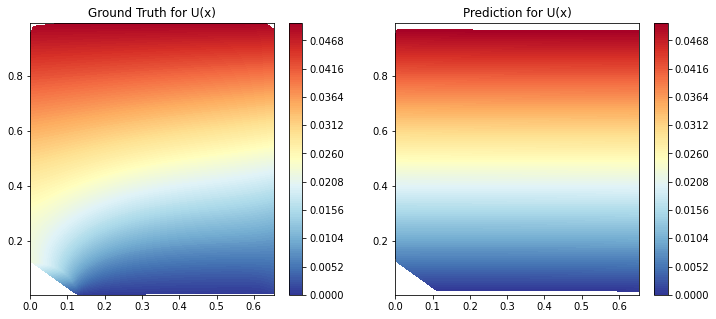

In [ ]:
# x, y are the x and y coords you want to plot at (can use the same form you have your training data in already),
# u would be whatever variable you want to plot
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
triang = tri.Triangulation(x_coord, y_coord)
apply_mask(triang, x_coord, y_coord, alpha=0.2)
tcf_a = axes[0].tricontourf(triang, u_gt, cmap='RdYlBu_r', levels=150)
fig.colorbar(tcf_a, ax=axes[0])
axes[0].set_title('Ground Truth for U(x)')

tcf = axes[1].tricontourf(triang, u, cmap='RdYlBu_r', levels=tcf_a.levels)
fig.colorbar(tcf, ax=axes[1])
axes[1].set_title('Prediction for U(x)')
plt.show()
plt.close()

In [ ]:
!python Plane_Stress_W-PINNs.py


start training...
v max : tensor(0.2750, grad_fn=<MaxBackward1>)
v min : tensor(0.2662, grad_fn=<MinBackward1>)
u max : tensor(0.1283, grad_fn=<MaxBackward1>)
u max : tensor(0.1167, grad_fn=<MinBackward1>)
x max tensor(1., grad_fn=<MaxBackward1>)
x min : tensor(0., grad_fn=<MinBackward1>)
dv/dx : tensor(0.0034, grad_fn=<MaxBackward1>)
epoch 1: loss_pde 1.25007749, loss_bc 0.08846081
epoch 1: loss 0.08846081 
v max : tensor(0.2596, grad_fn=<MaxBackward1>)
v min : tensor(0.2511, grad_fn=<MinBackward1>)
u max : tensor(0.1206, grad_fn=<MaxBackward1>)
u max : tensor(0.1094, grad_fn=<MinBackward1>)
x max tensor(1., grad_fn=<MaxBackward1>)
x min : tensor(0., grad_fn=<MinBackward1>)
dv/dx : tensor(0.0049, grad_fn=<MaxBackward1>)
epoch 2: loss_pde 1.25197995, loss_bc 0.07859980
epoch 2: loss 787.24993896 
v max : tensor(0.2482, grad_fn=<MaxBackward1>)
v min : tensor(0.2398, grad_fn=<MinBackward1>)
u max : tensor(0.1150, grad_fn=<MaxBackward1>)
u max : tensor(0.1040, grad_fn=<MinBackward1>)
x ma

In [ ]:
2coords_variable = torch.rand(2,5, 200).requires_grad_(True)

print(coords_variable.shape)


# Define the disp tensor as a function of the specific index of the coords_variable tensor
intermediate_value = coords_variable * 2
disp = intermediate_value + 1

# Compute the gradients on the specific index of the coords_variable tensor
strain = torch.autograd.grad(
    disp[0,:,0], coords_variable,
    grad_outputs=torch.ones_like(disp[0,:,0]),
    retain_graph=True,
    allow_unused=True,
    create_graph=True
    )[0]

# Print the strain and disp tensors
print(strain.shape)
print(disp.shape)
print(strain[:,:,0])


In [ ]:
import torch
import torch.nn as nn
from torch.autograd import Variable
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
# We consider Net as our solution u_theta(x,t)

"""
When forming the network, we have to keep in mind the number of inputs and outputs
In ur case: #inputs = 2 (x,t)
and #outputs = 1

You can add ass many hidden layers as you want with as many neurons.
More complex the network, the more prepared it is to find complex solutions, but it also requires more data.

Let us create this network:
min 5 hidden layer with 5 neurons each.
"""

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.hidden_layer1 = nn.Linear(2,5)
        self.hidden_layer2 = nn.Linear(5,5)
        self.hidden_layer3 = nn.Linear(5,5)
        self.hidden_layer4 = nn.Linear(5,5)
        self.hidden_layer5 = nn.Linear(5,5)
        self.output_layer = nn.Linear(5,1)

    def forward(self, x,t):
        inputs = torch.cat([x,t],axis=1) # combined two arrays of 1 columns each to one array of 2 columns
        layer1_out = torch.sigmoid(self.hidden_layer1(inputs))
        layer2_out = torch.sigmoid(self.hidden_layer2(layer1_out))
        layer3_out = torch.sigmoid(self.hidden_layer3(layer2_out))
        layer4_out = torch.sigmoid(self.hidden_layer4(layer3_out))
        layer5_out = torch.sigmoid(self.hidden_layer5(layer4_out))
        output = self.output_layer(layer5_out) ## For regression, no activation is used in output layer
        return output

In [ ]:

### (2) Model
net = Net()
net = net.to(device)
mse_cost_function = torch.nn.MSELoss() # Mean squared error
optimizer = torch.optim.Adam(net.parameters())

In [ ]:
## PDE as loss function. Thus would use the network which we call as u_theta
def f(x,t, net):
    u = net(x,t) # the dependent variable u is given by the network based on independent variables x,t
    ## Based on our f = du/dx - 2du/dt - u, we need du/dx and du/dt
    u_x = torch.autograd.grad(u.sum(), x, create_graph=True)[0]
    u_t = torch.autograd.grad(u.sum(), t, create_graph=True)[0]

    print(u_x.shape)

    print(u.shape)
    print('u.sum(): ', u.sum())
    pde = u_x - 2*u_t - u
    return pde

In [ ]:
## Data from Boundary Conditions
# u(x,0)=6e^(-3x)
## BC just gives us datapoints for training

# BC tells us that for any x in range[0,2] and time=0, the value of u is given by 6e^(-3x)
# Take say 500 random numbers of x
x_bc = np.random.uniform(low=0.0, high=2.0, size=(500,1))
t_bc = np.zeros((500,1))
# compute u based on BC
u_bc = 6*np.exp(-3*x_bc)

In [ ]:
### (3) Training / Fitting
iterations = 20000
previous_validation_loss = 99999999.0
for epoch in range(iterations):
    optimizer.zero_grad() # to make the gradients zero
    
    # Loss based on boundary conditions
    pt_x_bc = Variable(torch.from_numpy(x_bc).float(), requires_grad=False).to(device)
    pt_t_bc = Variable(torch.from_numpy(t_bc).float(), requires_grad=False).to(device)
    pt_u_bc = Variable(torch.from_numpy(u_bc).float(), requires_grad=False).to(device)
    
    net_bc_out = net(pt_x_bc, pt_t_bc) # output of u(x,t)
    mse_u = mse_cost_function(net_bc_out, pt_u_bc)
    
    # Loss based on PDE
    x_collocation = np.random.uniform(low=0.0, high=2.0, size=(500,1))
    t_collocation = np.random.uniform(low=0.0, high=1.0, size=(500,1))
    all_zeros = np.zeros((500,1))
    
    
    pt_x_collocation = Variable(torch.from_numpy(x_collocation).float(), requires_grad=True).to(device)
    pt_t_collocation = Variable(torch.from_numpy(t_collocation).float(), requires_grad=True).to(device)
    pt_all_zeros = Variable(torch.from_numpy(all_zeros).float(), requires_grad=False).to(device)
    
    f_out = f(pt_x_collocation, pt_t_collocation, net) # output of f(x,t)
    mse_f = mse_cost_function(f_out, pt_all_zeros)
    
    # Combining the loss functions
    loss = mse_u + mse_f
    
    
    loss.backward() # This is for computing gradients using backward propagation
    optimizer.step() # This is equivalent to : theta_new = theta_old - alpha * derivative of J w.r.t theta

    with torch.autograd.no_grad():
    	print(epoch,"Traning Loss:",loss.data)

In [ ]:
print(pt_x_collocation.shape)

In [ ]:
print(pt_t_collocation.shape)

torch.Size([500, 1])


NameError: ignored